# 머신러닝 심화 4일차 과제 — SMOTE + Random Forest 분류 (load_breast_cancer)

- **작성자**: 조태희
- **과정**: OZ 코딩 스쿨 AI 헬스케어 부트캠프 · 머신러닝 심화 4일차 (Extra Trees & Gradient Boosting)
- **과제 안내**: "sklearn.datasets 의 load_breast_cancer 데이터를 사용하여 SMOTE 기법을 적용하고 Random Forest Classification 실습을 진행해주세요."

## 🎯 학습 목표
1. **불균형 데이터**(클래스별 개수 차이가 큰 데이터)가 무엇이고, 왜 모델 평가를 어렵게 만드는지 이해합니다.
2. **SMOTE**의 원리를 이해하고, **훈련 세트에만** 적용해야 하는 이유(데이터 누수)를 설명할 수 있습니다.
3. Random Forest를 **SMOTE 적용 전/후**로 학습해 **같은 테스트 세트**에서 공정하게 비교합니다.
4. 의료 데이터에서 **악성 재현율(Recall)** 이 왜 중요한지 설명할 수 있습니다.
5. (보너스) 오늘 주제인 **Extra Trees**와도 간단히 비교합니다.

## 0. 환경 준비
그래프의 한글이 □□□처럼 깨지지 않도록 한글 글꼴 패키지를 설치하고, 필요한 라이브러리를 불러옵니다.

In [1]:
# 그래프 한글 깨짐을 막아 주는 패키지 설치 (Colab에서 실행, -q: 설치 로그를 짧게)
!pip install -q koreanize-matplotlib

In [2]:
# 불러오기만 하면 matplotlib의 기본 글꼴이 한글 글꼴(나눔고딕)로 자동 설정됩니다
import koreanize_matplotlib

In [3]:
import numpy as np                 # 숫자 배열 계산 라이브러리
import pandas as pd                # 표(DataFrame) 형태의 데이터를 다루는 라이브러리
import matplotlib as mpl           # 그래프 전체 설정(색 순서 등)용
import matplotlib.pyplot as plt    # 그래프 그리기 라이브러리
import seaborn as sns              # 히트맵(혼동행렬 그림) 그리기용

from sklearn.datasets import load_breast_cancer               # 유방암 진단 데이터
from sklearn.model_selection import train_test_split          # 훈련/테스트 세트 나누기
from sklearn.ensemble import RandomForestClassifier           # 랜덤 포레스트 분류기
from sklearn.ensemble import ExtraTreesClassifier             # 엑스트라 트리 분류기 (보너스 비교용)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # 평가 지표들
                             roc_auc_score, classification_report, confusion_matrix)  # (이어서) ROC-AUC, 리포트, 혼동행렬
# SMOTE는 scikit-learn이 아니라 imbalanced-learn(imblearn) 패키지에 들어 있습니다.
# (Colab에서 ModuleNotFoundError가 나면 !pip install -q imbalanced-learn 을 먼저 실행하세요)
from imblearn.over_sampling import SMOTE  # SMOTE 오버샘플링 도구 불러오기

RANDOM_STATE = 42                       # 재현성(다시 실행해도 같은 결과)을 위한 랜덤 시드
pd.set_option("display.precision", 4)   # 표의 소수점은 4자리까지 표시

# 그래프 공통 스타일 ------------------------------------------------------------
COLORS = ["#2a78d6", "#eb6834"]             # 색약이 있어도 구분되도록 검증된 색 (파랑, 주황)
mpl.rcParams["axes.spines.top"] = False     # 그래프 위쪽 테두리 숨기기
mpl.rcParams["axes.spines.right"] = False   # 그래프 오른쪽 테두리 숨기기
mpl.rcParams["axes.grid"] = True            # 격자 표시
mpl.rcParams["grid.color"] = "#e1e0d9"      # 격자는 아주 연한 회색 (데이터보다 눈에 덜 띄게)
mpl.rcParams["grid.linewidth"] = 0.8        # 격자 선은 가늘게
mpl.rcParams["axes.axisbelow"] = True       # 격자를 막대 아래에 그리기
print("준비 완료!")                           # 설정이 끝났다는 확인 메시지

준비 완료!


## 1. 데이터 불러오기 & 살펴보기
`load_breast_cancer()`는 유방 종괴(덩어리)에서 가는 바늘로 뽑은 세포(세침흡인, FNA)를 찍은 이미지로 **세포핵의 특징 30개**를 측정하고, 종양이 **악성인지 양성인지** 정답을 붙인 데이터입니다.

- **피처 이름 규칙**: 세포핵의 10가지 특성(radius 반지름, texture 질감, perimeter 둘레, area 면적, smoothness 매끄러움, compactness 조밀도, concavity 오목한 정도, concave points 오목한 지점 수, symmetry 대칭성, fractal dimension 프랙탈 차원)마다 **mean(평균)**, **error(표준오차)**, **worst(가장 큰 값 3개의 평균)** 3종류가 있어서 10 × 3 = 30개입니다.

In [4]:
data = load_breast_cancer()                              # 위스콘신 유방암 진단 데이터 불러오기
X = pd.DataFrame(data.data, columns=data.feature_names)  # 30개 피처를 표(DataFrame)로 만들기
y = pd.Series(data.target, name="target")                # 정답 라벨 (0 또는 1)

print("데이터 크기 (행, 열):", X.shape)                    # (환자 수, 피처 수)
print("결측치 총 개수:", int(X.isnull().sum().sum()))       # 모든 칸의 빈 값 개수 합계
print("라벨 이름(target_names) 확인:")                   # 소제목 출력
for i, name in enumerate(data.target_names):             # 라벨 번호(i)와 이름(name)을 하나씩 꺼내기
    print(f"  라벨 {i} = {name}")                         # 0번·1번 라벨이 각각 무슨 뜻인지 출력
X.head()                                                 # 앞 5줄 미리보기

데이터 크기 (행, 열): (569, 30)
결측치 총 개수: 0
라벨 이름(target_names) 확인:
  라벨 0 = malignant
  라벨 1 = benign


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


→ `target_names`를 확인해 보면 **라벨 0 = malignant(악성), 라벨 1 = benign(양성)** 입니다.
흔히 '병이 있음 = 1'이라고 생각하기 쉬운데 이 데이터는 **악성이 0**입니다. 그래서 뒤에서 악성 기준의 정밀도·재현율을 구할 때 `pos_label=0`을 꼭 지정해야 합니다. (결측치는 0개라 따로 처리할 필요가 없습니다.)

In [5]:
X.describe().T[["mean", "min", "max"]].head(10)  # 'mean' 계열 피처 10개의 평균·최솟값·최댓값 (.T: 행과 열을 뒤집어 보기 좋게)

,mean,min,max
mean radius,14.1273,6.9810,28.1100
mean texture,19.2896,9.7100,39.2800
mean perimeter,91.9690,43.7900,188.5000
mean area,654.8891,143.5000,2501.0000
mean smoothness,0.0964,0.0526,0.1634
mean compactness,0.1043,0.0194,0.3454
mean concavity,0.0888,0.0000,0.4268
mean concave points,0.0489,0.0000,0.2012
mean symmetry,0.1812,0.1060,0.3040
mean fractal dimension,0.0628,0.0500,0.0974


→ 피처마다 값의 크기가 크게 다릅니다. 예를 들어 mean area는 143.5 ~ 2501.0인데 mean smoothness는 0.0526 ~ 0.1634입니다. Random Forest 같은 트리 모델은 "기준값보다 큰가/작은가"로만 나누기 때문에 스케일링이 필요 없지만, 거리를 쓰는 SMOTE에는 영향을 줄 수 있습니다. (맨 끝 '다음에 해 볼 것'에서 다시 다룹니다.)

### 클래스 분포 확인 (불균형 정도)

In [6]:
counts = y.value_counts().sort_index()                                  # 라벨별 개수 (0, 1 순서로 정렬)
ratio = (y.value_counts(normalize=True).sort_index() * 100).round(2)    # 라벨별 비율(%) (normalize=True: 개수 대신 비율)
dist = pd.DataFrame({"개수": counts, "비율(%)": ratio})                   # 개수와 비율을 한 표로
dist.index = ["0: 악성(malignant)", "1: 양성(benign)"]                    # 행 이름을 알아보기 쉽게 변경
display(dist)                                                           # 표 출력
print(f"양성이 악성보다 {counts[1] / counts[0]:.2f}배 많습니다.")            # 불균형 정도

,개수,비율(%)
0: 악성(malignant),212,37.26
1: 양성(benign),357,62.74


양성이 악성보다 1.68배 많습니다.


→ 악성 212명(37.26%), 양성 357명(62.74%)으로 양성이 1.68배 많은 **약한 불균형**입니다.
- 불균형이 심하면 모델이 다수 클래스만 찍어도 정확도가 높게 나오는 함정이 생깁니다. (거의 모두가 양성인 데이터라면 전부 "양성"이라고만 답해도 정확도가 매우 높게 나옵니다.)
- 의료에서는 **소수 클래스(악성)를 놓치는 것**이 가장 위험하기 때문에, 정확도만 보지 않고 악성 기준 지표를 따로 봐야 합니다.

## 2. 훈련 / 테스트 세트 나누기
- `test_size=0.2`: 20%를 테스트용으로 떼어 둡니다. 테스트 세트는 **마지막 채점에만** 쓰는 '처음 보는 환자'입니다.
- `stratify=y`: 악성/양성 **비율을 훈련·테스트 세트에 똑같이 유지**합니다. 불균형 데이터에서 특히 중요합니다. 우연히 테스트 세트에 악성이 너무 적게 들어가면 평가 결과를 믿을 수 없기 때문입니다.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(  # 나눈 결과 4개(훈련 X, 테스트 X, 훈련 y, 테스트 y)를 차례로 받기
    X, y,                       # 나눌 대상: 피처 X와 정답 y
    test_size=0.2,              # 20%를 테스트 세트로
    stratify=y,                 # 악성/양성 비율을 양쪽에 똑같이 유지
    random_state=RANDOM_STATE,  # 매번 같은 방식으로 나누기 (재현성)
)
print("훈련 세트:", X_train.shape, "/ 테스트 세트:", X_test.shape)                 # (행, 열)
print("훈련 세트 라벨 개수:", y_train.value_counts().sort_index().to_dict())       # {0: 악성 수, 1: 양성 수}
print("테스트 세트 라벨 개수:", y_test.value_counts().sort_index().to_dict())      # 테스트 세트의 악성·양성 수
print(f"악성 비율 → 전체 {(y == 0).mean():.2%} / 훈련 {(y_train == 0).mean():.2%} / 테스트 {(y_test == 0).mean():.2%}")  # stratify 효과 확인

훈련 세트: (455, 30) / 테스트 세트: (114, 30)
훈련 세트 라벨 개수: {0: 170, 1: 285}
테스트 세트 라벨 개수: {0: 42, 1: 72}
악성 비율 → 전체 37.26% / 훈련 37.36% / 테스트 36.84%


→ 훈련 세트 455명(악성 170, 양성 285), 테스트 세트 114명(악성 42, 양성 72)입니다. 악성 비율이 전체 37.26%, 훈련 37.36%, 테스트 36.84%로 거의 같게 유지되었습니다.

## 3. SMOTE — 훈련 세트에만 적용하기

### SMOTE란?
**SMOTE(Synthetic Minority Over-sampling Technique, 합성 소수 클래스 오버샘플링)** 는 소수 클래스(여기서는 악성) 데이터를 **새로 만들어** 개수를 늘리는 방법입니다.

🧪 **비유**: 악성 샘플 A를 하나 고르고, A와 가장 비슷한 악성 이웃(기본 5개) 중 하나인 B를 고른 뒤, **A와 B를 잇는 선 위의 아무 지점**에 새 점을 찍습니다. 똑같이 복사하는 게 아니라 "그럴듯한 중간 샘플"을 만드는 것이죠.

공식: `새 샘플 = A + (B − A) × (0~1 사이 난수)`

### ⚠️ 왜 훈련 세트에만 적용할까? (데이터 누수, data leakage)
- 테스트 세트는 **"모델이 한 번도 본 적 없는 실제 환자"** 역할을 해야 공정한 시험이 됩니다.
- 나누기 **전에** SMOTE를 하면, 테스트 세트에 들어갈 악성 샘플을 재료로 만든 합성 샘플이 훈련 세트에 섞여 들어갑니다. 모델이 시험 문제를 **살짝 엿보고** 공부한 셈이라, 성능이 실제보다 좋게 나올 수 있습니다. 이것을 **데이터 누수**라고 합니다.
- 또 테스트 세트에 합성(가짜) 샘플이 섞이면 실제 환자 분포가 아닌 데이터로 채점하게 됩니다.
- 그래서 순서는 반드시 **① 훈련/테스트 분할 → ② 훈련 세트에만 SMOTE → ③ 손대지 않은 테스트 세트로 평가** 입니다.

In [8]:
# 🔍 SMOTE가 새 샘플을 만드는 공식 직접 따라 해 보기 (피처 2개짜리 장난감 예시)
a = np.array([10.0, 20.0])    # 악성 샘플 A (피처 2개)
b = np.array([14.0, 26.0])    # A와 가까운 악성 이웃 B
gap = 0.25                    # 0~1 사이 난수 (SMOTE는 무작위로 뽑지만, 여기선 예시로 0.25로 고정)
new = a + (b - a) * gap       # A에서 B 쪽으로 25%만큼 이동한 지점
print("새로 만든 샘플:", new)    # A와 B를 잇는 선분 위의 점이 만들어짐

새로 만든 샘플: [11.  21.5]


In [9]:
smote = SMOTE(random_state=RANDOM_STATE)                       # SMOTE 객체 만들기 (k_neighbors=5가 기본값)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)  # ⚠️ 훈련 세트에만 적용! (테스트 세트는 건드리지 않음)

smote_table = pd.DataFrame({                                   # SMOTE 전/후 라벨 개수를 나란히 놓은 표 만들기
    "SMOTE 전": y_train.value_counts().sort_index(),           # 적용 전 라벨별 개수
    "SMOTE 후": y_train_sm.value_counts().sort_index(),        # 적용 후 라벨별 개수
})
smote_table.index = ["악성(0)", "양성(1)"]                       # 행 이름 바꾸기
display(smote_table)                                           # 전/후 비교 표 출력

print("훈련 세트 크기:", X_train.shape, "→", X_train_sm.shape)    # 합성된 악성 샘플만큼 행이 늘어남
print("새로 만든 합성 샘플 수:", len(X_train_sm) - len(X_train), "개")  # 늘어난 행 수 = 합성 샘플 수
print("테스트 세트 라벨 개수 (변화 없음):", y_test.value_counts().sort_index().to_dict())  # 테스트 세트는 그대로인지 확인

,SMOTE 전,SMOTE 후
악성(0),170,285
양성(1),285,285


훈련 세트 크기: (455, 30) → (570, 30)
새로 만든 합성 샘플 수: 115 개
테스트 세트 라벨 개수 (변화 없음): {0: 42, 1: 72}


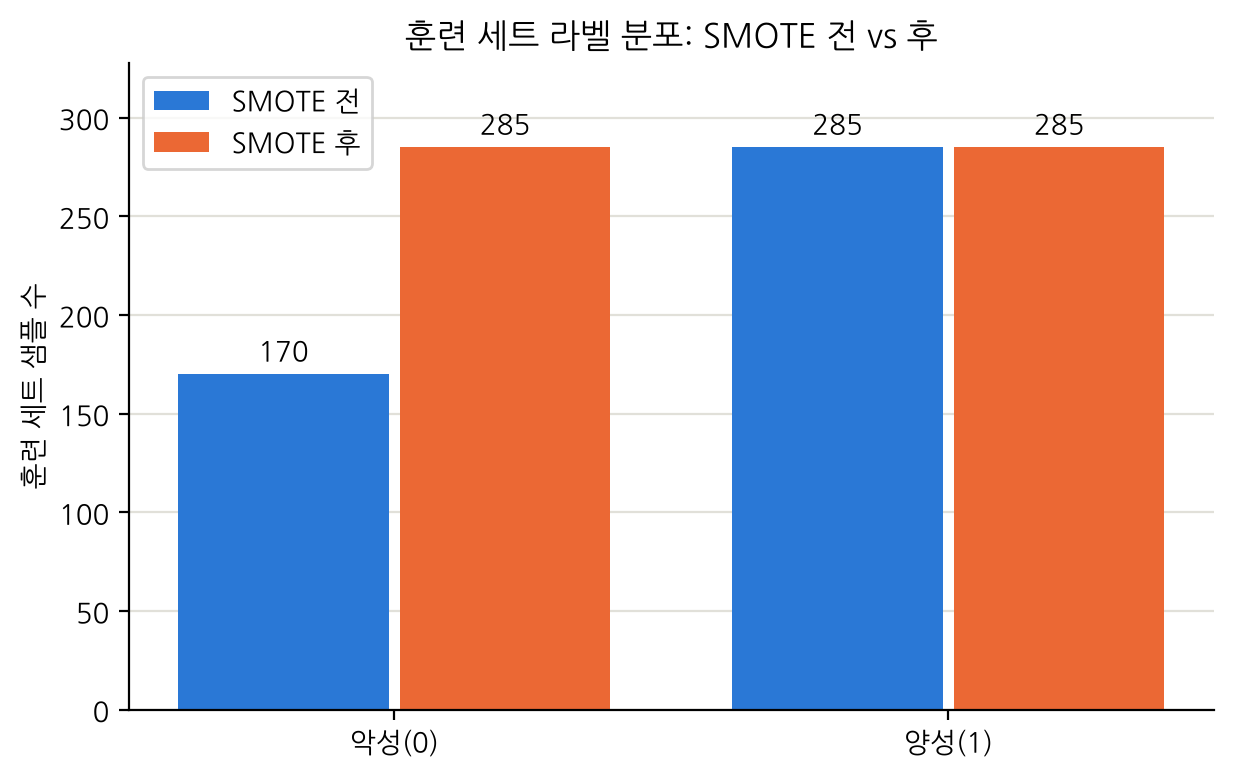

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.2))                       # 그래프 영역 만들기
x = np.arange(len(smote_table))                                # 막대 묶음 위치: 0(악성), 1(양성)
bars_before = ax.bar(x - 0.2, smote_table["SMOTE 전"], width=0.38, color=COLORS[0], label="SMOTE 전")  # 왼쪽 막대: 적용 전
bars_after = ax.bar(x + 0.2, smote_table["SMOTE 후"], width=0.38, color=COLORS[1], label="SMOTE 후")   # 오른쪽 막대: 적용 후
ax.bar_label(bars_before, padding=3)                           # 막대 위에 개수 표시
ax.bar_label(bars_after, padding=3)                            # 막대 위에 개수 표시
ax.set(xticks=x, xticklabels=smote_table.index, ylabel="훈련 세트 샘플 수",  # x축 눈금 위치·이름, y축 이름
       title="훈련 세트 라벨 분포: SMOTE 전 vs 후")                 # 축 눈금·이름·제목
ax.set_ylim(0, smote_table.values.max() * 1.15)                # 막대 위 숫자가 잘리지 않게 위쪽 여백
ax.grid(axis="x", visible=False)                               # 세로 격자는 숨기기
ax.legend()                                                    # 범례
plt.show()                                                     # 출력

→ SMOTE 후 훈련 세트의 악성이 170개 → 285개로 늘어 양성(285개)과 1:1이 되었습니다. 새로 생긴 115개는 모두 기존 악성 샘플 사이에 만든 **합성 샘플**이고, 테스트 세트(악성 42, 양성 72)는 그대로입니다.

## 4. Random Forest 학습 (SMOTE 미적용 vs 적용)
🌳 **Random Forest(랜덤 포레스트)** 는 훈련 데이터를 조금씩 다르게 뽑아(부트스트랩) 만든 결정 트리 여러 개가 **다수결 투표**로 예측하는 앙상블 모델입니다. 각 트리는 나눌 때마다 피처 일부만 무작위로 골라 보기 때문에 트리들이 서로 달라지고, 그 덕분에 트리 하나보다 과적합(훈련 데이터에만 지나치게 맞춰지는 것)에 강합니다.

두 모델은 **학습 데이터만 다르고** 나머지 설정(`n_estimators=200`, `random_state=42`)은 똑같이 맞춰 공정하게 비교합니다.

In [11]:
rf_base = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)   # SMOTE 미적용 모델 (트리 200개)
rf_base.fit(X_train, y_train)                                                   # 원본 훈련 세트로 학습

rf_smote = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)  # SMOTE 적용 모델 (설정 동일)
rf_smote.fit(X_train_sm, y_train_sm)                                            # SMOTE로 균형 맞춘 훈련 세트로 학습
print("두 모델 학습 완료!")                                                       # 학습이 끝났다는 확인 메시지

두 모델 학습 완료!


## 5. 같은 테스트 세트로 평가하기

여기서는 **악성 = 우리가 찾아야 할 대상(positive)** 으로 보고 지표를 계산합니다.
- **정확도(Accuracy)**: 전체 중 맞힌 비율
- **정밀도(Precision, 악성)**: 모델이 "악성"이라고 한 환자 중 진짜 악성의 비율 → 낮으면 **괜한 추가 검사(오경보)** 가 늘어납니다.
- **재현율(Recall, 악성)**: 진짜 악성 환자 중 모델이 찾아낸 비율 → 낮으면 **암 환자를 놓칩니다.**
- **F1 점수**: 정밀도와 재현율의 조화평균 (둘 중 하나만 높아서는 높게 나오지 않는 '균형 점수')
- **ROC-AUC**: 무작위로 고른 악성 환자 1명과 양성 환자 1명을 비교했을 때, 모델이 악성 환자 쪽에 더 높은 '악성 점수'를 줄 확률입니다. 기준값(threshold)과 상관없이 **줄 세우는 능력 자체**를 봅니다. (1에 가까울수록 좋음)

🩺 **왜 악성 재현율이 특히 중요할까?** 악성을 양성으로 잘못 판단하면(거짓 음성, False Negative) 치료 시기를 놓쳐 생명이 위험해질 수 있습니다. 반대로 양성을 악성으로 잘못 판단하면(거짓 양성, False Positive) 추가 검사 비용과 불안이 생기지만, 조직검사 같은 추가 검사로 바로잡을 기회가 있습니다. 그래서 암 진단에서는 **놓치는 악성을 줄이는 것(재현율)** 을 특히 중요하게 봅니다.

> ⚠️ sklearn의 `precision_score`, `recall_score`, `f1_score`는 기본적으로 **라벨 1을 positive**로 계산합니다. 이 데이터에서 1은 '양성(benign)'이므로, 악성 기준으로 보려면 `pos_label=0`을 꼭 지정해야 합니다.

In [12]:
def evaluate(model, name, verbose=True):  # model: 평가할 모델, name: 출력용 이름, verbose: 자세히 출력할지 여부
    """같은 테스트 세트(X_test, y_test)로 모델을 평가해 지표 딕셔너리와 혼동행렬을 돌려주는 함수"""
    pred = model.predict(X_test)                        # 테스트 세트 예측 (0 또는 1)
    proba_benign = model.predict_proba(X_test)[:, 1]    # 각 환자가 양성(1)일 확률 → ROC-AUC 계산용
    cm = confusion_matrix(y_test, pred, labels=[0, 1])  # 혼동행렬 (행: 실제 0·1, 열: 예측 0·1)
    result = {                                                        # 지표 이름(키)과 값을 딕셔너리에 담기
        "정확도": accuracy_score(y_test, pred),                       # 전체 중 맞힌 비율
        "정밀도(악성)": precision_score(y_test, pred, pos_label=0),   # 악성이라 예측한 것 중 진짜 악성 비율
        "재현율(악성)": recall_score(y_test, pred, pos_label=0),      # 진짜 악성 중 찾아낸 비율
        "F1(악성)": f1_score(y_test, pred, pos_label=0),              # 정밀도와 재현율의 조화평균
        "ROC-AUC": roc_auc_score(y_test, proba_benign),              # 양성 확률로 계산해도 악성 확률로 계산해도 같은 값
        "놓친 악성(FN)": int(cm[0, 1]),                                # 실제 악성인데 양성으로 예측 (가장 위험한 오류)
        "오경보(FP)": int(cm[1, 0]),                                   # 실제 양성인데 악성으로 예측
    }
    if verbose:                                                       # 자세히 출력하기로 했다면
        print(f"===== {name} =====")                                  # 모델 이름 제목 출력
        for key in ["정확도", "정밀도(악성)", "재현율(악성)", "F1(악성)", "ROC-AUC"]:  # 비율 지표들만 골라서
            print(f"{key}: {result[key]:.4f}")                        # 소수 4자리로 출력
        print(f"놓친 악성(FN): {result['놓친 악성(FN)']}명 / 오경보(FP): {result['오경보(FP)']}명")  # 오류 개수 출력
        print("\n[classification_report] 클래스별 정밀도·재현율·F1 (support = 실제 환자 수)")  # 소제목 출력
        print(classification_report(y_test, pred, target_names=["악성(0)", "양성(1)"], digits=4))  # 클래스별 지표 표 (소수 4자리)
    return result, cm                                                 # 비교표용 결과와 혼동행렬 반환

In [13]:
res_base, cm_base = evaluate(rf_base, "RandomForest (SMOTE 미적용)")  # SMOTE 없이 학습한 모델 평가

===== RandomForest (SMOTE 미적용) =====
정확도: 0.9561
정밀도(악성): 0.9512
재현율(악성): 0.9286
F1(악성): 0.9398
ROC-AUC: 0.9931
놓친 악성(FN): 3명 / 오경보(FP): 2명

[classification_report] 클래스별 정밀도·재현율·F1 (support = 실제 환자 수)
              precision    recall  f1-score   support

       악성(0)     0.9512    0.9286    0.9398        42
       양성(1)     0.9589    0.9722    0.9655        72

    accuracy                         0.9561       114
   macro avg     0.9551    0.9504    0.9526       114
weighted avg     0.9561    0.9561    0.9560       114



In [14]:
res_smote, cm_smote = evaluate(rf_smote, "RandomForest + SMOTE")     # SMOTE로 학습한 모델 평가 (같은 테스트 세트!)

===== RandomForest + SMOTE =====
정확도: 0.9474
정밀도(악성): 0.9091
재현율(악성): 0.9524
F1(악성): 0.9302
ROC-AUC: 0.9929
놓친 악성(FN): 2명 / 오경보(FP): 4명

[classification_report] 클래스별 정밀도·재현율·F1 (support = 실제 환자 수)
              precision    recall  f1-score   support

       악성(0)     0.9091    0.9524    0.9302        42
       양성(1)     0.9714    0.9444    0.9577        72

    accuracy                         0.9474       114
   macro avg     0.9403    0.9484    0.9440       114
weighted avg     0.9485    0.9474    0.9476       114



> 📌 `classification_report`의 **macro avg**는 두 클래스 점수의 단순 평균, **weighted avg**는 클래스별 환자 수(support)로 가중 평균한 값입니다.

### 혼동행렬(Confusion Matrix)로 보기
혼동행렬은 **실제(행) × 예측(열)** 으로 몇 명씩 맞히고 틀렸는지 세는 표입니다. 대각선(왼쪽 위 → 오른쪽 아래)이 맞힌 수입니다.

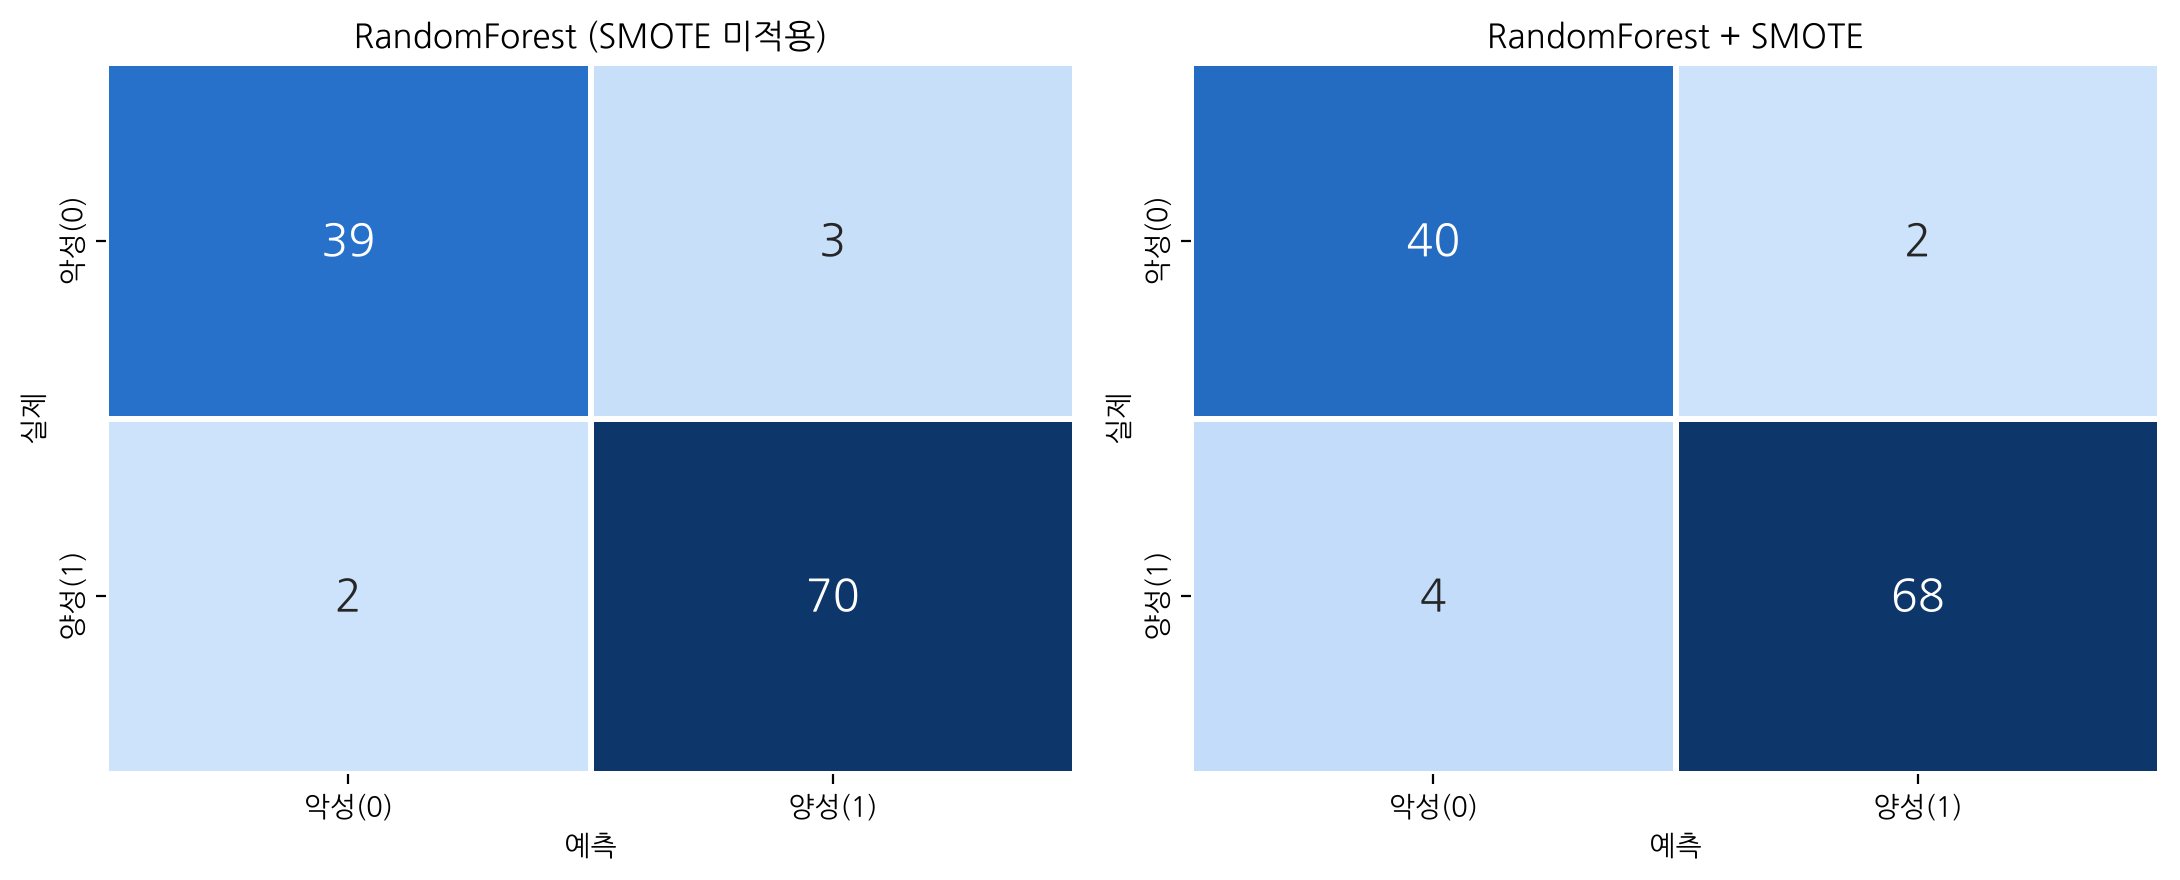

In [15]:
blue_ramp = mpl.colors.LinearSegmentedColormap.from_list(                  # 색 목록을 이어 붙여 색 지도(cmap) 만들기
    "blue_ramp", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])  # 연한 파랑 → 진한 파랑 (한 가지 색의 진하기 = 숫자 크기)
tick_names = ["악성(0)", "양성(1)"]                                          # 축 눈금 이름

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))                           # 1행 2열
for ax, cm, title in zip(axes, [cm_base, cm_smote],                         # (그릴 위치, 혼동행렬, 제목)을 짝지어
                         ["RandomForest (SMOTE 미적용)", "RandomForest + SMOTE"]):  # 두 모델을 차례로 그리기
    sns.heatmap(cm, annot=True, fmt="d", cmap=blue_ramp, cbar=False, ax=ax,  # annot: 칸 안에 숫자, fmt="d": 정수로 표시
                xticklabels=tick_names, yticklabels=tick_names,                # x·y축 눈금 이름
                linewidths=2, linecolor="white", annot_kws={"size": 16})     # 칸 사이 흰 간격, 숫자 크게
    ax.set(title=title, xlabel="예측", ylabel="실제")                         # 제목·축 이름
    ax.grid(False)                                                          # 히트맵에는 격자 끄기
plt.tight_layout()                                                          # 간격 자동 조정
plt.show()                                                                  # 출력

→ **SMOTE 미적용**: 악성 42명 중 39명을 맞히고 **3명을 놓쳤고**, 양성 72명 중 2명을 악성으로 잘못 판단(오경보)했습니다.
→ **SMOTE 적용**: 악성 40명을 맞혀 **놓친 악성이 2명으로 1명 줄었지만**, 오경보는 4명으로 2명 늘었습니다.

## 6. 비교표 (+ 보너스: Extra Trees)
🌲 **Extra Trees(Extremely Randomized Trees, 엑스트라 트리)** 는 Random Forest와 비슷하지만 더 무작위적입니다.
- 기본 설정에서 부트스트랩 없이 **훈련 데이터 전체**를 씁니다.
- 나눌 기준값(threshold)을 가장 좋은 값을 찾아 정하는 대신, **무작위로 뽑은 후보 중에서** 고릅니다.
- 그래서 학습이 빠르고, 트리끼리 더 달라져 과적합에 강한 편입니다.

같은 SMOTE 훈련 세트로 학습해서 비교표에 함께 넣습니다.

In [16]:
et_smote = ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE)  # Extra Trees (설정은 RF와 동일하게)
et_smote.fit(X_train_sm, y_train_sm)                                          # SMOTE 적용된 훈련 세트로 학습
res_et, cm_et = evaluate(et_smote, "ExtraTrees + SMOTE", verbose=False)       # 같은 테스트 세트로 평가 (출력은 생략)

compare = pd.DataFrame(                                                       # 세 모델의 결과를 한 표로
    [res_base, res_smote, res_et],                                            # 표의 각 행이 될 결과 3개
    index=["RandomForest (SMOTE 미적용)", "RandomForest + SMOTE", "ExtraTrees + SMOTE"],  # 행 이름
)
compare                                                                       # 비교표 출력

,정확도,정밀도(악성),재현율(악성),F1(악성),ROC-AUC,놓친 악성(FN),오경보(FP)
RandomForest (SMOTE 미적용),0.9561,0.9512,0.9286,0.9398,0.9931,3,2
RandomForest + SMOTE,0.9474,0.9091,0.9524,0.9302,0.9929,2,4
ExtraTrees + SMOTE,0.9649,0.9524,0.9524,0.9524,0.9931,2,2


## 7. 피처 중요도 (Top 10)
Random Forest는 각 피처가 트리의 **불순도(섞여 있는 정도)를 얼마나 줄였는지**를 모아서 중요도로 알려 줍니다. 모두 더하면 1입니다.

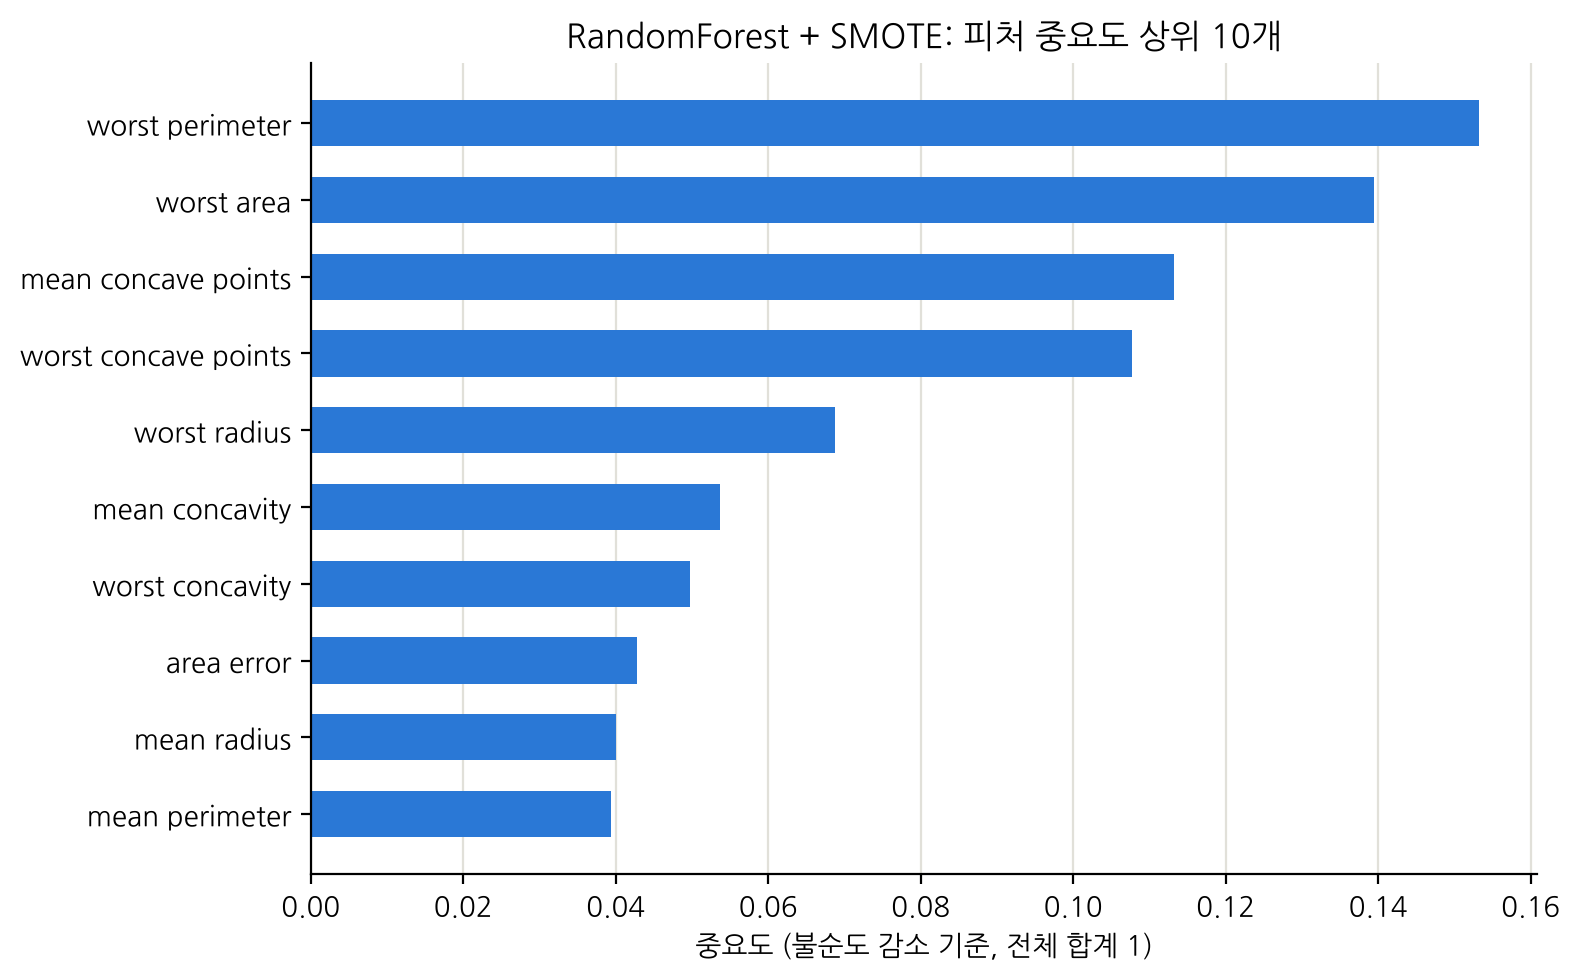

worst perimeter         0.1532
worst area              0.1394
mean concave points     0.1132
worst concave points    0.1077
worst radius            0.0687
mean concavity          0.0537
worst concavity         0.0498
area error              0.0428
mean radius             0.0400
mean perimeter          0.0394
dtype: float64


In [17]:
importances = pd.Series(rf_smote.feature_importances_, index=X.columns)  # 피처별 중요도 (합계 1)
top10 = importances.sort_values(ascending=False).head(10)               # 중요도 상위 10개

fig, ax = plt.subplots(figsize=(8, 5))                                   # 그래프 영역 만들기
ax.barh(top10.index[::-1], top10.values[::-1], color=COLORS[0], height=0.6)  # 가로 막대 ([::-1]: 가장 큰 값이 맨 위에 오도록 뒤집기)
ax.set(title="RandomForest + SMOTE: 피처 중요도 상위 10개",                    # 제목
       xlabel="중요도 (불순도 감소 기준, 전체 합계 1)")                       # 제목·축 이름
ax.grid(axis="y", visible=False)                                         # 가로 격자는 숨기기
plt.tight_layout()                                                       # 간격 자동 조정
plt.show()                                                               # 출력
print(top10.round(4))                                                    # 숫자로도 확인

In [18]:
# 상위 4개 피처가 악성/양성에서 실제로 얼마나 다른지 평균으로 확인
top4_means = X[top10.index[:4]].groupby(y.map({0: "악성(0)", 1: "양성(1)"})).mean()  # 라벨별 평균
top4_means.round(4)                                                                  # 소수 4자리로 표시

,worst perimeter,worst area,mean concave points,worst concave points
target,,,,
악성(0),141.3703,1422.2863,0.0880,0.1822
양성(1),87.0059,558.8994,0.0257,0.0744


→ 상위 4개는 **worst perimeter(0.1532), worst area(0.1394), mean concave points(0.1132), worst concave points(0.1077)** 로, 세포핵의 **크기(둘레·면적)** 와 **윤곽의 오목한 지점 수(concave points)** 관련 피처입니다. 라벨별 평균을 보면 네 피처 모두 악성 쪽이 훨씬 큽니다. 악성 세포는 핵이 크고 윤곽이 불규칙한 경향이 있다는 의학적 상식과도 방향이 맞습니다.
> 참고: 불순도 기준 중요도는 서로 비슷한 정보를 가진 피처(radius·perimeter·area처럼)끼리 중요도를 나눠 갖기 때문에, 순위를 "인과관계"로 해석하면 안 됩니다.

## 8. 결과 해석

| 모델 | 정확도 | 정밀도(악성) | 재현율(악성) | F1(악성) | ROC-AUC | 놓친 악성 | 오경보 |
|---|---|---|---|---|---|---|---|
| RandomForest (SMOTE 미적용) | 0.9561 | 0.9512 | 0.9286 | 0.9398 | 0.9931 | 3명 | 2명 |
| RandomForest + SMOTE | 0.9474 | 0.9091 | 0.9524 | 0.9302 | 0.9929 | 2명 | 4명 |
| ExtraTrees + SMOTE | 0.9649 | 0.9524 | 0.9524 | 0.9524 | 0.9931 | 2명 | 2명 |

1. **SMOTE를 적용하자 악성 재현율이 0.9286 → 0.9524로 올랐습니다.** 테스트 세트의 악성 42명 중 놓친 환자가 3명 → 2명으로 1명 줄었습니다.
2. **대신 정밀도와 정확도는 떨어졌습니다.** 오경보가 2명 → 4명으로 늘어 정밀도는 0.9512 → 0.9091, 정확도는 0.9561 → 0.9474가 되었습니다. 악성 샘플이 많아진 데이터로 배우면서 모델이 "악성" 쪽으로 더 쉽게 판단하게 된, 전형적인 **재현율 ↔ 정밀도 트레이드오프**입니다.
3. **ROC-AUC는 거의 같습니다(0.9931 vs 0.9929).** SMOTE가 모델의 근본적인 구분 능력을 높였다기보다는, 판단 기준을 악성 쪽으로 조금 옮긴 효과에 가깝습니다.
4. **솔직한 결론: 이 데이터에서 SMOTE의 이득은 작습니다.** 악성 37.26% : 양성 62.74%의 약한 불균형이고, 테스트 세트의 악성이 42명뿐이라 1명 차이는 우연일 가능성도 큽니다. SMOTE는 불균형이 훨씬 심한 데이터에서 효과가 더 뚜렷하게 나타나는 편입니다.
5. **보너스, Extra Trees + SMOTE**는 이번 테스트 세트에서 정확도(0.9649)와 악성 F1(0.9524)이 세 모델 중 가장 높았고, 놓친 악성 2명·오경보 2명으로 두 오류 모두 가장 적은 수준(다른 모델과 동률 포함)이었습니다. 다만 이것도 114명 기준 1~2명 차이라서, 확실한 결론을 내리려면 아래의 교차검증으로 여러 번 확인해야 합니다.

### 📚 다음에 해 볼 것
- **교차검증 + SMOTE**: `imblearn.pipeline.Pipeline`에 SMOTE와 모델을 함께 넣고 `cross_val_score`를 쓰면, 각 fold의 훈련 부분에만 SMOTE가 적용되어 누수 없이 여러 번 평가할 수 있습니다.
- **SMOTE 대신 다른 방법과 비교**: `class_weight="balanced"`(소수 클래스 오답에 더 큰 벌점), 또는 `predict_proba`의 판단 기준을 0.5보다 낮춰 악성을 더 적극적으로 잡는 **임계값 조정**
- **스케일링 후 SMOTE**: SMOTE는 내부에서 가까운 이웃(KNN)을 거리로 찾기 때문에 area처럼 값이 큰 피처의 영향을 크게 받습니다. 표준화한 뒤 SMOTE를 적용하면 합성 샘플이 달라질 수 있습니다.
- 오늘의 또 다른 주제인 **Gradient Boosting**(`GradientBoostingClassifier`)과도 같은 방식으로 비교해 보기